### Mini Project — DBSCAN

#### Anomaly Detection in Sensor Readings

In [33]:
import numpy as np

np.random.seed(33)

# Normal sensor readings — dense clusters (2 operating modes)
normal_mode1 = np.random.normal(loc=[50, 60], scale=3, size=(100, 2))  # temperature, pressure
normal_mode2 = np.random.normal(loc=[80, 30], scale=3, size=(100, 2))

# Anomalies — sparse, scattered readings (sensor malfunctions/unusual events)
anomalies = np.random.uniform(low=[20, 10], high=[110, 90], size=(15, 2))

X = np.vstack([normal_mode1, normal_mode2, anomalies])
true_labels = np.array([0]*100 + [1]*100 + [-1]*15)  # used only for validation; never shown to the model

- Apply scaling
- Plot a k-distance graph for min_samples=5 and find the "elbow" to choose a good eps
- Run DBSCAN and check how many clusters and how many noise points are found
- Draw a scatter plot, highlighting the noise points with a different colour/marker
- Compare: how many of the DBSCAN "noise" points match the actual injected anomalies (true_labels == -1)? (an informal accuracy check, even though the method is unsupervised)
- Bonus: try K-Means (K=2) on the same data. Can it identify the anomalies separately, or does it force them into the normal clusters?

In [34]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

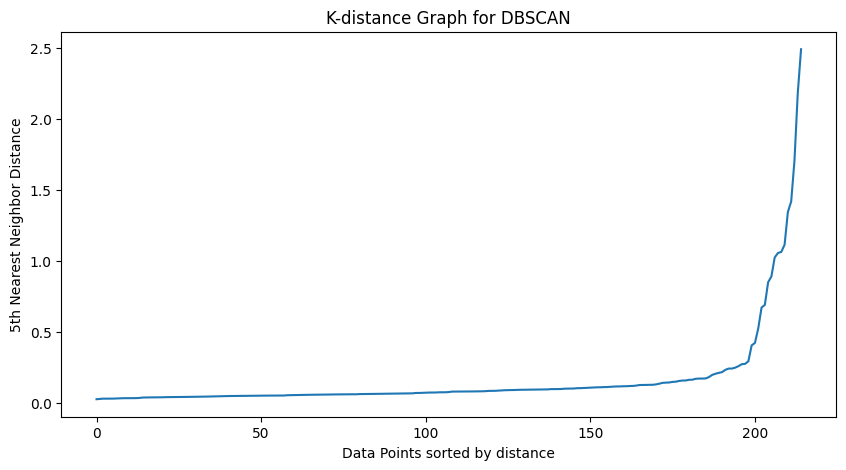

In [35]:
from matplotlib import pyplot as plt
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))
plt.plot(distances)
plt.title('K-distance Graph for DBSCAN')
plt.xlabel('Data Points sorted by distance')
plt.ylabel('5th Nearest Neighbor Distance')
plt.show()

In [36]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

for eps in [0.3, 0.4]:
    dbscan = DBSCAN(eps=eps, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_scaled)
    
    n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    noise_count = list(dbscan_labels).count(-1)
    
    if n_clusters > 1:
        silhouette = silhouette_score(X_scaled, dbscan_labels)
    else:
        silhouette = float('nan')
    
    print(f'For eps={eps}:')
    print(f'Clusters found: {n_clusters}')
    print(f'Noise points: {noise_count}')
    print(f'Silhouette Score: {silhouette:.3f}\n')


For eps=0.3:
Clusters found: 2
Noise points: 15
Silhouette Score: 0.768

For eps=0.4:
Clusters found: 2
Noise points: 13
Silhouette Score: 0.781



In [37]:
noise_points = true_labels == -1
noise_count = np.sum(noise_points)
print(f'Actual noise points: {noise_count}')

Actual noise points: 15


In [38]:
# k Means
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

print(f'K-Means Clusters found: {len(set(kmeans_labels))}')
print(f'K-Means Silhouette Score: {silhouette_score(X_scaled, kmeans_labels):.3f}')

K-Means Clusters found: 2
K-Means Silhouette Score: 0.813


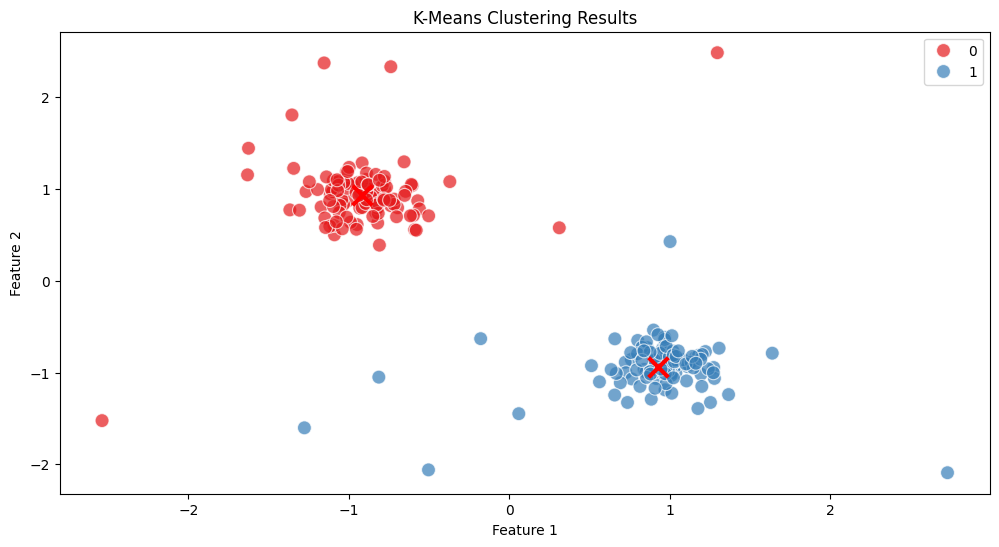

In [39]:
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=kmeans_labels, palette='Set1', s=100, alpha=0.7)
sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1], c='red', marker='x', s=200, linewidths=3)
plt.title('K-Means Clustering Results')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.show()
